In [1]:
import openmc
import numpy as np
import math
import pathlib

In [2]:
# Material Definition
p = 'wo'
m1 = openmc.Material()
m1.add_nuclide('Ge74',1.0,p)
m1.set_density('g/cc',5.16)

m2 = openmc.Material()
m2.add_nuclide('U238',1.0,p)
m2.set_density('g/cc',19.0)

m3 = openmc.Material()
m3.add_nuclide('Pb208',1.0,p)
m3.set_density('g/cc',11.3)

materials = openmc.Materials([m1,m2,m3])

In [3]:
# Surface Specification
s1 = openmc.model.RectangularParallelepiped(-100,100,-100,100,-100,100,boundary_type='vacuum')
s2 = openmc.Sphere(r=5)
s3 = openmc.model.RightCircularCylinder((20,0,25),10,4,'z')
s4 = openmc.Sphere(x0=20,y0=0,z0=0,r=5)
s5 = openmc.model.RightCircularCylinder((20,0,20),5,4,'z')
s6 = openmc.model.RightCircularCylinder((20,0,20),17,6,'z')

# Cell specification
c1 = openmc.Cell(fill=None,region=-s1&+s2&+s6&+s4)
c2 = openmc.Cell(fill=None,region=-s2)
c4 = openmc.Cell(fill=m1,region=-s3)
c5 = openmc.Cell(fill=m2,region=-s4)
c6 = openmc.Cell(fill=None,region=-s5)
c7 = openmc.Cell(fill=m3, region=-s6&+s3&+s5)
c8 = openmc.Cell(fill=None,region=+s1)

geometry = openmc.Geometry([c1,c2,c4,c5,c6,c7,c8])

In [4]:
# Tally specification
f1 = openmc.Tally()
f1.filters = []
f1.filters.append(openmc.ParticleProductionFilter(['electron','proton','gamma'],
                                                  energies=np.logspace(-10,10,5,base=10)))

#f8.filters.append(openmc.CellFilter(c1))
f8.scores = ['current']


f4 = openmc.Tally()
f4.filters = []
f4.filters.append(openmc.CellFilter(c2))
f4.scores = ['flux'] 

tallies = openmc.Tallies(tallies=[f1,f4])

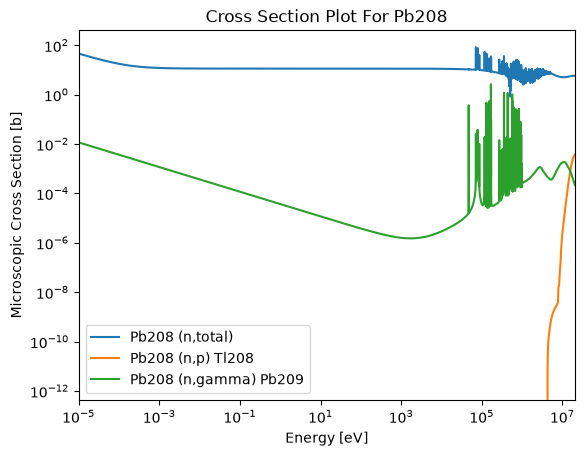

In [5]:
import matplotlib.pyplot as plt

fig = openmc.plotter.plot_xs(
    reactions = {
        'Pb208': ['(n,total)','(n,p)','(n,gamma)'],
    }
)
plt.show()

Time dependent sources 

In [6]:
settings = openmc.Settings()
settings.run_mode='fixed source'

# We need two sources.

background = openmc.IndependentSource()

source = openmc.IndependentSource()
source.space = openmc.stats.Point((0,0,1))
source.angle = openmc.stats.Monodirectional((0,0,-1)) 
source.particle = 'neutron'
source.energy = openmc.stats.delta_function(1e7) # energy in eV 


# Enable photon transport
settings.photon_transport = True 

# fluorescence photons and auger electrons enabled
settings.atomic_relaxation = True 

settings.source = [background,source]
# settings.source_sampling = 

# History settings
settings.particles = 1000
settings.batches = 1000

In [7]:
model = openmc.model.Model(geometry, materials, settings, tallies)

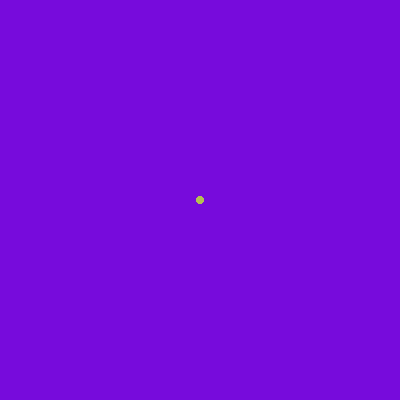

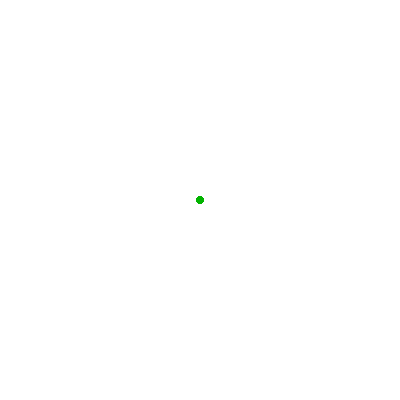

In [8]:
plots = openmc.Plots()
w = 1
origin = (0,0,0)

plot = openmc.SlicePlot()
plot.basis = 'xz'
plot.origin = origin
plot.width = (w,w)
plot.pixels = (400, 400)
plot.color_by= 'cell'
plots.append(plot)

plot = openmc.SlicePlot()
plot.basis = 'yz'
plot.origin = origin
plot.width = (w,w)
plot.pixels = (400, 400)
plot.color_by= 'material'
plots.append(plot)
openmc.plot_inline(plots)

In [9]:
sp_filename = model.run()

                                %%%%%%%%%%%%%%%
                           %%%%%%%%%%%%%%%%%%%%%%%%
                        %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                      %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                   %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                                    %%%%%%%%%%%%%%%%%%%%%%%%
                                     %%%%%%%%%%%%%%%%%%%%%%%%
                 ###############      %%%%%%%%%%%%%%%%%%%%%%%%
                ##################     %%%%%%%%%%%%%%%%%%%%%%%
                ###################     %%%%%%%%%%%%%%%%%%%%%%%
                ####################     %%%%%%%%%%%%%%%%%%%%%%
                #####################     %%%%%%%%%%%%%%%%%%%%%
                ######################     %%%%%%%%%%%%%%%%%%%%
                #######################     %%%%%%%%%%%%%%%%%%
                 #######################     %%%%%%%%%%%%%%%%%
                 #####################

In [10]:
with openmc.StatePoint(sp_filename) as sp:
    for key in (sp.tallies.keys()):
        print(sp.tallies)
        tally_name = sp.tallies[key].name

        results = sp.get_tally(name=tally_name)
        df = results.get_pandas_dataframe()
        print(df)
        print(f"{tally_name} = {df['mean'].sum()} +/- {df['std. dev.'].sum()}\n")

{np.int32(1): Tally
	ID             =	1
	Name           =	
	Filters        =	ParticleProductionFilter
	Nuclides       =	total
	Scores         =	['flux']
	Estimator      =	analog
	Multiply dens. =	True}
   particleproduction                                  nuclide score     mean  \
             particle energy low [eV] energy high [eV]                          
0            electron        1.00e-10         1.00e-05   total  flux 0.00e+00   
1            electron        1.00e-05         1.00e+00   total  flux 0.00e+00   
2            electron        1.00e+00         1.00e+05   total  flux 0.00e+00   
3            electron        1.00e+05         1.00e+10   total  flux 0.00e+00   
4                  H1        1.00e-10         1.00e-05   total  flux 0.00e+00   
5                  H1        1.00e-05         1.00e+00   total  flux 0.00e+00   
6                  H1        1.00e+00         1.00e+05   total  flux 0.00e+00   
7                  H1        1.00e+05         1.00e+10   total  flux 